# Regret Matching

Positive cumulative external regret gives extra probability to actions that would have produced a better payoff in hindsight. Both players update from full counterfactual payoffs.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Match probabilities to regret

When every accumulated regret is nonpositive, use a uniform distribution.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from gallery.games import ZERO_SUM, gap, show_mixes, trace_plot


def match(regret):
    positive = np.maximum(regret, 0)
    return (
        positive / positive.sum() if positive.sum() > 0 else np.full(len(regret), 1 / len(regret))
    )

## Average policies and guarantees

The updates below use expected payoffs of the current mixed strategies. The gap is evaluated on the average strategies.

Per-round row external regret 0.01515 | Column 0.01284
Average-strategy best-response gap 0.02798 | Expected payoff 0.28562


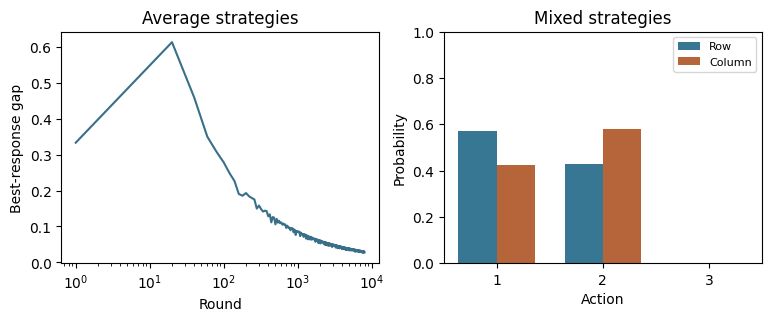

In [3]:
A = ZERO_SUM.copy()
row_regret = np.zeros(3)
col_regret = np.zeros(3)
row_sum = np.zeros(3)
col_sum = np.zeros(3)
history = []
for t in range(1, 8001):
    p = match(row_regret)
    q = match(col_regret)
    value = p @ A @ q
    row_regret += A @ q - value
    col_regret += value - p @ A
    row_sum += p
    col_sum += q
    if t == 1 or t % 20 == 0:
        history.append((t, gap(A, row_sum / t, col_sum / t)))
p, q = row_sum / t, col_sum / t
print(f"Per-round row external regret {row_regret.max()/t:.5f} | Column {col_regret.max()/t:.5f}")
print(f"Average-strategy best-response gap {gap(A,p,q):.5f} | Expected payoff {p@A@q:.5f}")
assert np.isclose(gap(A, p, q), (row_regret.max() + col_regret.max()) / t)
trace_plot(history, p, q)
plt.show()

## Reading the result

In a two-player zero-sum game, the two average external regrets add to the average-strategy gap. The assertion checks that identity directly.

## References

[Hart and Mas-Colell, A Simple Adaptive Procedure Leading to Correlated Equilibrium (2000), regret-matching background](https://doi.org/10.1111/1468-0262.00153)

[Zinkevich et al., Regret Minimization in Games with Incomplete Information (2007), external regret and average strategy](https://proceedings.neurips.cc/paper/2007/hash/08d98638c6fcd194a4b1e6992063e944-Abstract.html)

[Payoff matrix and best-response diagnostics](../../gallery/games.py)